Урок в прозе: https://proproprogs.ru/nn_pytorch/pytorch-funkcii-aktivacii-v-rnn-dvunapravlennye-bidirectional-rnn-sloi

В рекуррентных нейронных сетях мы использовали функцию активации tanh, а в других сетях - ReLU. 

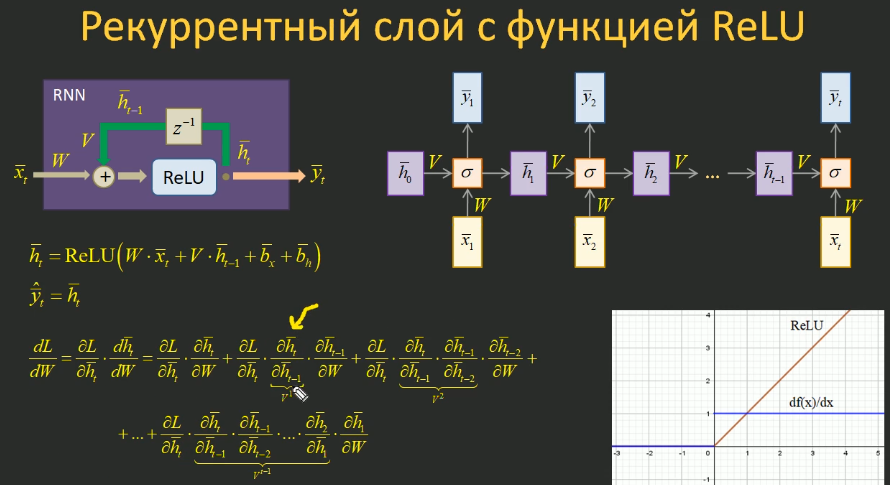

Если дифференцировать функцию потерь по матрице весов, то из-за рекуррентности у нас будет много слагаемых (по каждому h_t-1). В каждом слагаемом есть хотя бы один множитель dht/dh_t-1. Производная от него равна матрице V (принимаем, что производная от самой ReLU всю равна 1). Соответственно в каждом слагаемом будет матрица V, сколько-то раз умноженная саму на себя. Если ее определитель будет больше 1, то комплекс примет огромное значение, и наоборот, если меньше 1, то затухнет.

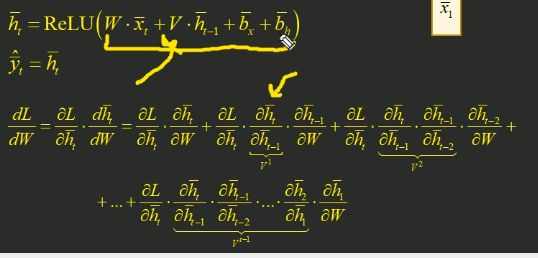

Что же будет, если взять гиперболический тангенс? 

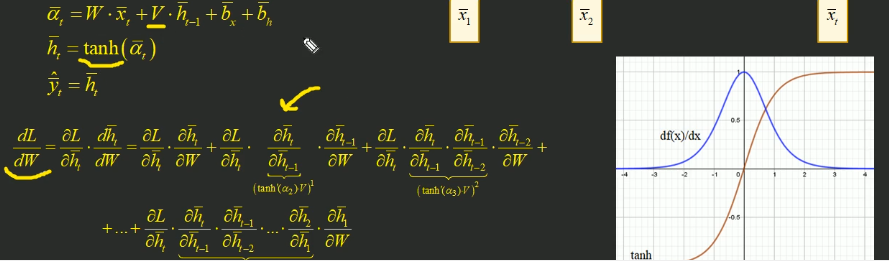

Здесь мы никуда не ушли от перемножения матриц V, но из-за того, что производная tanh в основном меньше 1, этот рост компенсируется. Можно было бы использовать и сигмоиду, но у сигмоиды производная едва превышает 0.2  
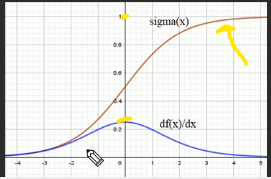

Наибольшее количество перемножений V будет у первых элементов цепочки, там градиент будет меньше. Поэтому мдель больше учится на последних элементах цепочки.  
В общем побороть затухание не так просто. Для этог опридуманы специальные архитектуры - LSTM и GRU

Но все же есть прием, который позволяет справиться с этим даже в RNN сетях. Бывает, что цепочка дана сразу вся целиком (нам не нужно предсказывать какое-то там следующее значение). Тогда можно пройти ее в двух направлениях и сформировать два вектора скрытого состояния

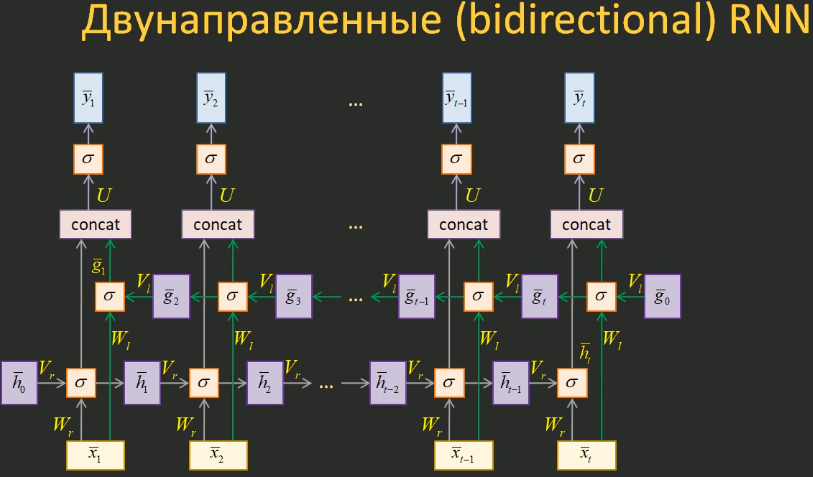